In [1]:
from sklearn.datasets import load_iris
data = load_iris()

In [2]:
# split the data into features and target
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

In [3]:
# intialize and train (fitting) the model
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [4]:
# predict the target for the test data
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

1.0

## correlation
Correlation measures tht strength and direction of the relationship between two variables

``` pearson's correlation r = Cov(x,y) / (varX * varY)``` -> ranges from -1 to 1.
-1 -> As X increases, Y decreases in a perfectly linear fashion

Cov -> 

```Cov(X, Y) = (E(Xi - Xmean)(Yi - Ymean))/n```  # E = summation
```Var(X) = sum(Xi-Xmean)^2/n```
```Var(Y) = 

### interpreting correlation

r = +1.0 -> perfect positive correlation
r = +0.7 -> strong postitve correlation
r about 0 -> no linear relationship

r = -0.7 -> strong negative correlation
r = -1.0 -> perfect negative correlation

Correlation != causation


In [5]:
import pandas as pd # for dfs and .corr() method
import numpy as np # for np.corrcoef() method
import seaborn as sns # for heatmap visualization
import matplotlib.pyplot as plt # for plotting the heatmap

In [6]:
# create a sample data
np.random.seed(42)
n = 100
df = pd.DataFrame({
    'hours_studied': np.random.uniform(1, 10, n),
    'sleep_hours': np.random.uniform(4, 10, n),
    'phone_hours': np.random.uniform(0, 6, n)
})
# Target Variable Creation or Synthetic Data Generation (feature engineering)
df['exam_score'] = df['hours_studied'] * 8 + df['sleep_hours'] * 2+ df['phone_hours'] * 3 + np.random.normal(0, 5, n)

In [ ]:
# Calculate the correlation matrix
corr_matrix = df.corr()
print(corr_matrix)

               hours_studied  sleep_hours  phone_hours  exam_score
hours_studied       1.000000    -0.034033    -0.037654    0.937591
sleep_hours        -0.034033     1.000000    -0.146354    0.096361
phone_hours        -0.037654    -0.146354     1.000000    0.189135
exam_score          0.937591     0.096361     0.189135    1.000000


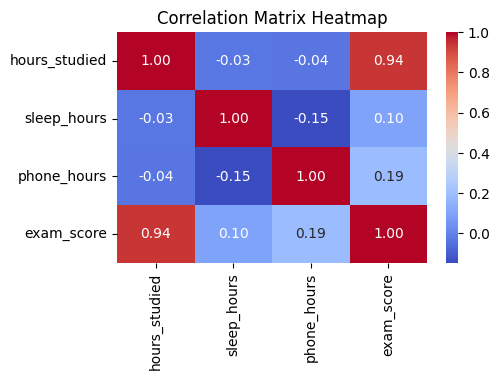

In [8]:
# heatmap visualization
plt.figure(figsize=(5, 3))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()

## Hypothesis testing and p-values
Hypothesis testing - this is a structured way to evaluate a claim using data

example:
Imagine you change the curriculum and want to know:
Did students actually perform better or did it just happen by chance?
-H0 - null hypothesis -> No change/ there is no effect.
The new curriculum made no difference

-H1- alternative hypothesis.
The new curriculum improved the scores.


## The p-value.
p-value -> tells us how likely our observed result is if the null hypothesis were true

p-value < 0.05 -> prob of null hypothesis being true is very low, thus reject the null hypothesis
p-value >=0.05 -> prob is high, the result could be random, dont reject null hypothesis


In [1]:
from scipy import stats
import numpy as np

# Sample data for two groups
# scenario 1: Did the new curriculum improve scores.
np.random.seed(42)
old_curriculum_scores = np.random.normal(65, 12, 50)  # mean=65, std=12, n=50
new_curriculum_scores = np.random.normal(72, 11, 50)  # mean=72, std=11, n=50

# independent samples t-test
t_stat, p_value = stats.ttest_ind(old_curriculum_scores, new_curriculum_scores)

# Print the results
print(f"old curriculum mean: {old_curriculum_scores.mean():.1f}")
print(f"new curriculum mean: {new_curriculum_scores.mean():.1f}")
print(f"t-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.3f}")


      

old curriculum mean: 62.3
new curriculum mean: 72.2
t-statistic: -4.742
p-value: 0.000
